In [1]:
%pip install opencv-python numpy matplotlib scikit-image scipy

Note: you may need to restart the kernel to use updated packages.


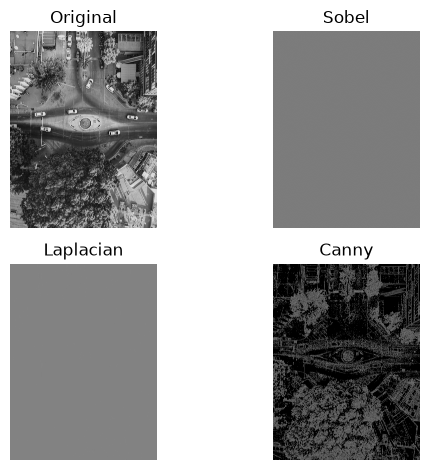

Canny generally produces cleaner and thinner edges.


In [1]:
import cv2
import matplotlib.pyplot as plt

img=cv2.imread("outdoor.jpg",0)
images=[img,cv2.Sobel(img,cv2.CV_64F,1,1),cv2.Laplacian(img,cv2.CV_64F),cv2.Canny(img,100,200)]
titles=["Original","Sobel","Laplacian","Canny"]

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(images[i],cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()
print("Canny generally produces cleaner and thinner edges.")

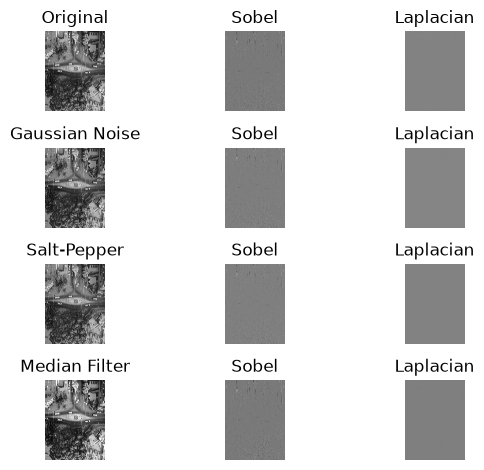

Laplacian is more noise-sensitive. Gaussian blur helps Gaussian noise; median blur helps salt-and-pepper noise.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img=cv2.imread("outdoor.jpg",0)
np.random.seed(42)
gauss=np.clip(img+np.random.normal(0,25,img.shape),0,255).astype(np.uint8)
sp=img.copy()
m=np.random.random(img.shape)
sp[m<0.03]=0
sp[m>0.97]=255

for i,im in enumerate([img,gauss,sp,cv2.medianBlur(sp,5)]):
    plt.subplot(4,3,i*3+1)
    plt.imshow(im,cmap="gray")
    plt.title(["Original","Gaussian Noise","Salt-Pepper","Median Filter"][i])
    plt.axis("off")
    plt.subplot(4,3,i*3+2)
    plt.imshow(cv2.Sobel(im,cv2.CV_64F,1,0),cmap="gray")
    plt.title("Sobel")
    plt.axis("off")
    plt.subplot(4,3,i*3+3)
    plt.imshow(cv2.Laplacian(im,cv2.CV_64F),cmap="gray")
    plt.title("Laplacian")
    plt.axis("off")
plt.tight_layout()
plt.show()
print("Laplacian is more noise-sensitive. Gaussian blur helps Gaussian noise; median blur helps salt-and-pepper noise.")

In [4]:
import cv2
import heapq
from collections import Counter

img=cv2.imread("outdoor.jpg",0)
data=img.flatten().tolist()
original=len(data)*8
rle=0
i=0

while i<len(data):
    j=i+1
    while j<len(data) and data[j]==data[i] and j-i<4294967295:
        j+=1
    rle+=40
    i=j

freq=Counter(data)
heap=[[n,[[v,""]]] for v,n in freq.items()]
heapq.heapify(heap)

if len(heap)==1:
    codes={heap[0][1][0][0]:"0"}
else:
    while len(heap)>1:
        a=heapq.heappop(heap)
        b=heapq.heappop(heap)
        for p in a[1]: p[1]="0"+p[1]
        for p in b[1]: p[1]="1"+p[1]
        heapq.heappush(heap,[a[0]+b[0],a[1]+b[1]])
    codes={p[0]:p[1] for p in heap[0][1]}

huffman=sum(freq[v]*len(c) for v,c in codes.items())

for name,bits in [("Original",original),("RLE",rle),("Huffman",huffman)]:
    print(name,"Bits:",bits)
    if name!="Original":
        print("Reduction:",round((1-bits/original)*100,2),"%")

Original Bits: 96000000
RLE Bits: 457392800
Reduction: -376.45 %
Huffman Bits: 91710675
Reduction: 4.47 %


Low PSNR: 42.78 SSIM: 0.991
Medium PSNR: 36.56 SSIM: 0.961
High PSNR: 30.32 SSIM: 0.866


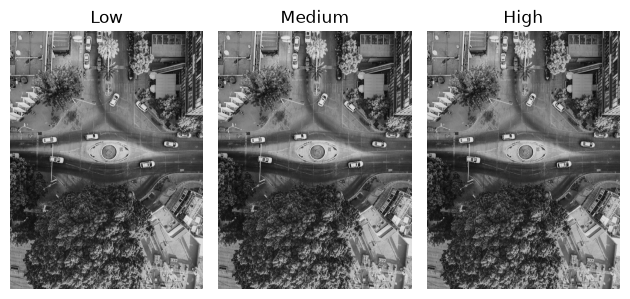

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio,structural_similarity

img=cv2.imread("outdoor.jpg",0)
img=img[:img.shape[0]//8*8,:img.shape[1]//8*8]
Q=np.ones((8,8))*20

for i,(name,s) in enumerate([("Low",0.5),("Medium",1),("High",2)]):
    out=np.zeros_like(img,dtype=float)
    for y in range(0,img.shape[0],8):
        for x in range(0,img.shape[1],8):
            b=img[y:y+8,x:x+8].astype(float)-128
            d=cv2.dct(b)
            out[y:y+8,x:x+8]=cv2.idct(np.round(d/(Q*s))*(Q*s))+128
    out=np.clip(out,0,255).astype(np.uint8)
    print(name,"PSNR:",round(peak_signal_noise_ratio(img,out,data_range=255),2),"SSIM:",round(structural_similarity(img,out,data_range=255),3))
    plt.subplot(1,3,i+1)
    plt.imshow(out,cmap="gray")
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

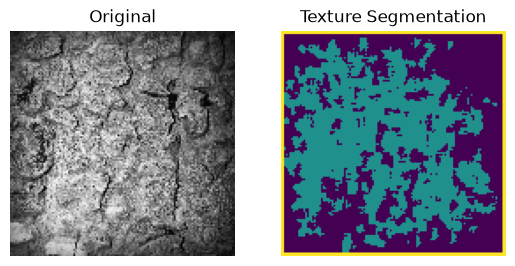

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix,graycoprops
from sklearn.cluster import KMeans

img=cv2.resize(cv2.imread("texture.jpg",0),(128,128))
q=(img//32).astype(np.uint8)
f=np.zeros((128,128,3))

for y in range(2,126):
    for x in range(2,126):
        g=graycomatrix(q[y-2:y+3,x-2:x+3],[1],[0],levels=8,symmetric=True,normed=True)
        f[y,x]=[graycoprops(g,p)[0,0] for p in ["contrast","energy","homogeneity"]]

X=f.reshape(-1,3)
X=(X-X.mean(0))/(X.std(0)+1e-8)
seg=KMeans(n_clusters=3,random_state=42,n_init=10).fit_predict(X).reshape(128,128)

plt.subplot(1,2,1)
plt.imshow(img,cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(seg,cmap="viridis")
plt.title("Texture Segmentation")
plt.axis("off")
plt.show()

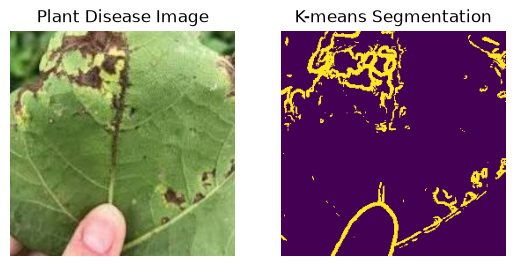

Intensity detects colour differences, gradient detects boundaries, and variance detects texture.


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

img=cv2.resize(cv2.imread("plant_disease.jpg"),(256,256))
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
intensity=gray/255
gx=cv2.Sobel(gray,cv2.CV_32F,1,0)
gy=cv2.Sobel(gray,cv2.CV_32F,0,1)
gradient=cv2.magnitude(gx,gy)
gradient/=gradient.max()+1e-8
mean=cv2.blur(gray.astype(float),(7,7))
var=np.maximum(cv2.blur(gray.astype(float)**2,(7,7))-mean**2,0)
var/=var.max()+1e-8
X=np.stack([intensity,gradient,var],axis=-1).reshape(-1,3)
X=(X-X.mean(0))/(X.std(0)+1e-8)
seg=KMeans(n_clusters=2,random_state=42,n_init=10).fit_predict(X).reshape(gray.shape)

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.title("Plant Disease Image")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(seg,cmap="viridis")
plt.title("K-means Segmentation")
plt.axis("off")
plt.show()
print("Intensity detects colour differences, gradient detects boundaries, and variance detects texture.")